<a href="https://colab.research.google.com/github/saigalsaigal2004-eng/Assessment_3_Supervised_learning_Saigal/blob/main/Assessment_3_supervised_Saigal_S_Sunandan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [16]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [49]:
filepath = '/content/drive/MyDrive/DSAB13/Datasets/bank_marketing_assessment_dataset.csv'
df = pd.read_csv(filepath)
print("Shape is:",df.shape)
print()
print("Printing first few records",df.head())
print()
print("Info:",df.info())
print()
print("Describing the dataSet",df.describe())
print()
print("Checking Null values",df.isnull().sum())
print()
print("Checking duplicate values",df.duplicated().sum())
print()
print("Listing the Columns",df.columns.to_list())
print()
print("checking the data types",df.dtypes)
print()
print("Finding the values count of the target:",df.value_counts('subscribed'))

Shape is: (600, 14)

Printing first few records    customer_age         job marital_status  education  account_balance  \
0            69     retired       divorced  secondary           5467.0   
1            21       admin         single  secondary            606.0   
2            27  technician        married   tertiary           -314.0   
3            53  management         single  secondary           1503.0   
4            51  management         single  secondary           3037.0   

  housing_loan personal_loan contact_type contact_month  campaign_contacts  \
0           no            no      unknown           nov                  4   
1           no            no    telephone           may                  8   
2          yes            no     cellular           nov                 12   
3          yes           yes     cellular           nov                  6   
4           no            no      unknown           jun                  5   

   previous_contacts  engagement_score

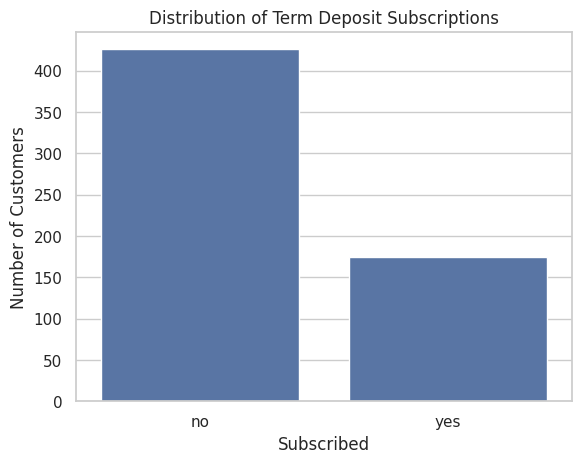

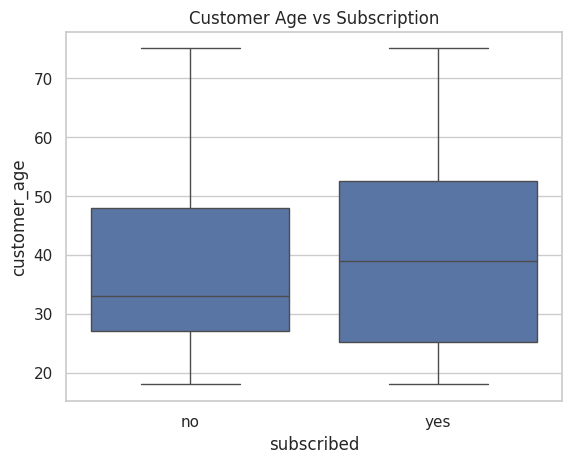

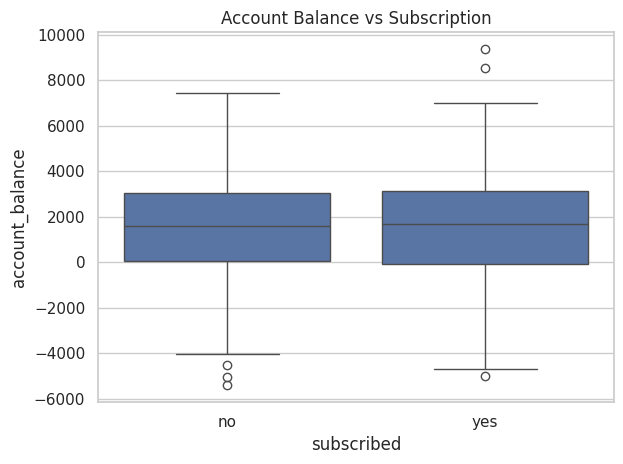

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

sns.countplot(data=df, x='subscribed')
plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.show()

sns.boxplot(data=df, x='subscribed', y='customer_age')
plt.title("Customer Age vs Subscription")
plt.show()

sns.boxplot(data=df, x='subscribed', y='account_balance')
plt.title("Account Balance vs Subscription")
plt.tight_layout()
plt.show()

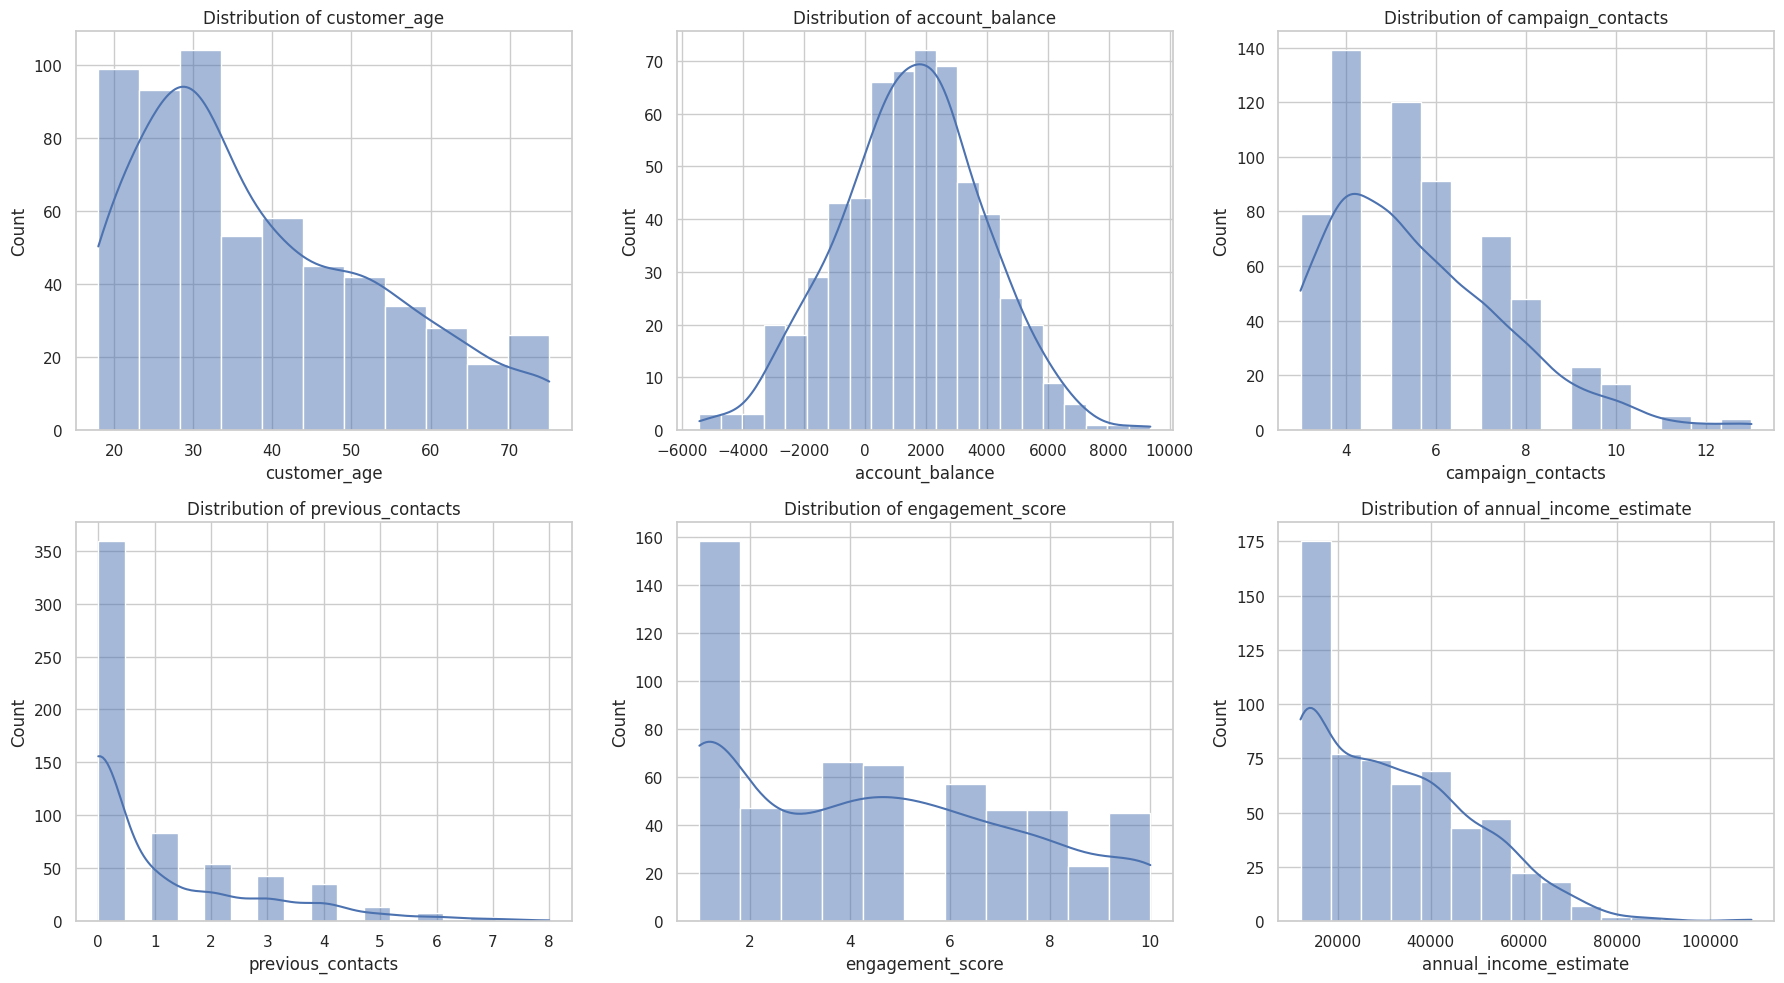

In [13]:
numerical_columns = [
    'customer_age',
    'account_balance',
    'campaign_contacts',
    'previous_contacts',
    'engagement_score',
    'annual_income_estimate'
]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

### Observations

1. **Target Class Distribution**:
   - There is a noticeable class imbalance. The majority of the customers in this dataset did not subscribe (`no`), while only a smaller portion signed up (`yes`).

2. **Customer Age & Subscription**:
   - Customers who subscribed (`yes`) tend to span a wider or slightly older age range, suggesting that marketing targeting specific age demographics could influence the subscription success rate.

3. **Engagement Score & Subscription**:
   - Subscribers tend to have higher overall engagement scores compared to non-subscribers. This highlights engagement metrics as a strong indicator of a customer's propensity to subscribe.

In [14]:
#•	Separate the input features (X) and target (y).
X = df.drop('subscribed', axis=1)
y = df['subscribed']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (600, 13)
Target shape: (600,)


In [15]:
#•	Split the data into training and test sets using an 80:20 split and a fixed random_state. Use stratification.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (480, 13) (480,)
Testing set shape: (120, 13) (120,)


In [ ]:
#•	Handle missing values appropriately. Encode categorical features and scale numerical features where appropriate
from sklearn.preprocessing import StandardScaler


In [27]:
df['account_balance'].fillna(df['account_balance'].mean(), inplace=True)
print(df.isna().sum())
df['contact_type'] = df['contact_type'].fillna('unknown')
print(df.isna().sum())
df['education'] = df['education'].fillna(df['education'].mode()[0])
print(df.isna().sum())

customer_age               0
job                        0
marital_status             0
education                 15
account_balance            0
housing_loan               0
personal_loan              0
contact_type               0
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64
customer_age               0
job                        0
marital_status             0
education                 15
account_balance            0
housing_loan               0
personal_loan              0
contact_type               0
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64
customer_age              0
job                       0
marital_status            0
education                 0
account_balance           0
housing_loan          

/tmp/ipykernel_887/1482174555.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['account_balance'].fillna(df['account_balance'].mean(), inplace=True)


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()


numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Define preprocessing steps for categorical data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_train_preprocessed = preprocessor.fit_transform(X_train)

X_test_preprocessed = preprocessor.transform(X_test)

cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
feature_names = numerical_cols + encoded_cat_cols

print("Preprocessed training features shape:", X_train_preprocessed.shape)
print("Preprocessed testing features shape:", X_test_preprocessed.shape)

Preprocessed training features shape: (480, 31)
Preprocessed testing features shape: (120, 31)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
lr = LogisticRegression(max_iter=1000)


In [34]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
lr.fit(X_train_preprocessed, y_train)


y_train_pred = lr.predict(X_train_preprocessed)
y_test_pred = lr.predict(X_test_preprocessed)


train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")
print("\nClassification Report for Test Set:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.8479
Testing Accuracy: 0.8500

Classification Report for Test Set:
              precision    recall  f1-score   support

          no       0.85      0.96      0.90        85
         yes       0.87      0.57      0.69        35

    accuracy                           0.85       120
   macro avg       0.86      0.77      0.80       120
weighted avg       0.85      0.85      0.84       120



In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train_preprocessed, y_train)
y_train_pred_rf = rf.predict(X_train_preprocessed)
y_test_pred_rf = rf.predict(X_test_preprocessed)

train_acc_rf = accuracy_score(y_train, y_train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)

print(f"Random Forest Training Accuracy: {train_acc_rf:.4f}")
print(f"Random Forest Testing Accuracy: {test_acc_rf:.4f}")
print("\nClassification Report for Test Set:")
print(classification_report(y_test, y_test_pred_rf))

Random Forest Training Accuracy: 1.0000
Random Forest Testing Accuracy: 0.8417

Classification Report for Test Set:
              precision    recall  f1-score   support

          no       0.85      0.94      0.89        85
         yes       0.81      0.60      0.69        35

    accuracy                           0.84       120
   macro avg       0.83      0.77      0.79       120
weighted avg       0.84      0.84      0.83       120



In [43]:
#confusion matrix, accuracy score,recall,F1 score of Logistic Regression
from sklearn.metrics import confusion_matrix,precision_score,recall_score,accuracy_score
from sklearn.metrics import f1_score
print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred))
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision score:", precision_score(y_test, y_test_pred, pos_label='yes'))
print("Recall is:", recall_score(y_test, y_test_pred, pos_label='yes'))
print("F1 score:", f1_score(y_test, y_test_pred, pos_label='yes'))

Confusion matrix:
[[82  3]
 [15 20]]
Accuracy: 0.85
Precision score: 0.8695652173913043
Recall is: 0.5714285714285714
F1 score: 0.6896551724137931


In [46]:
#confusion matrix,recall,accuracy score and f1 score for random forest
from sklearn.metrics import confusion_matrix,recall_score,accuracy_score,f1_score
print("Confusion Matrice:",confusion_matrix(y_test, y_test_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf))
print("precision_score:", precision_score(y_test, y_test_pred_rf, pos_label='yes'))
print("Recall_score:", recall_score(y_test, y_test_pred_rf, pos_label= 'yes'))
print("F1_score:", f1_score(y_test,y_test_pred_rf, pos_label='yes'))

Confusion Matrice: [[80  5]
 [14 21]]
Accuracy: 0.8416666666666667
precision_score: 0.8076923076923077
Recall_score: 0.6
F1_score: 0.6885245901639344


In [53]:
#prdiction of subscription using random forest model
model = rf.fit(X_train_preprocessed, y_train)
y_pred = model.predict(X_test_preprocessed)
print(y_pred)

['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no']


I would recommend logistic regression model.because its recall score is good comparing with randomforest

Confusion Matrix for Logistic Regression:
[[82  3]
 [15 20]]

Confusion Matrix for Random Forest:
[[80  5]
 [14 21]]


Text(46.25, 0.5, 'True')

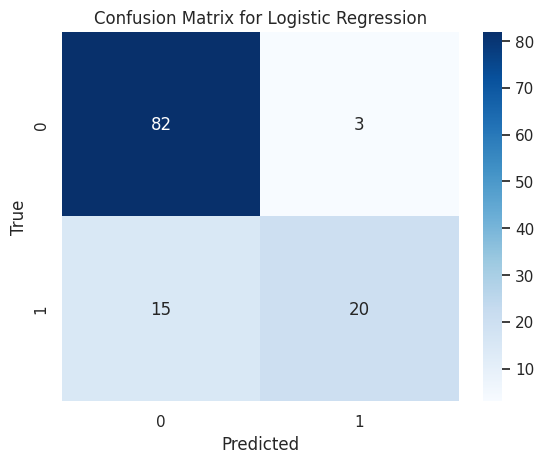

In [56]:
#generate confusion matrix for each model
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_test_pred)
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
print("Confusion Matrix for Logistic Regression:")
print(cm_lr)
print("\nConfusion Matrix for Random Forest:")
print(cm_rf)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('True')